# Notebook 06: Division Events — How Their Spacing Shapes the Dynamics

**Goal:** Derive division events from an environment that records the system, then vary the
time between records and watch the same qubit move from indivisible, to divisible (a Markov chain at
the record times), to nearly frozen.

By the end of this notebook you will be able to:
- Derive a division event from a full system-plus-environment unitary, with no extra postulate
- Predict the dynamics for any record spacing δt from one number, ωδt
- Locate the spacing below which the process is divisible over every interval
- Show that imperfect records no longer guarantee division events, and measure when they fail

**Sources.** "Paper 1, 2, 3" are Jacob A. Barandes's papers:
- Paper 1: "The Stochastic-Quantum Correspondence", arXiv:2302.10778 (*Philosophy of Physics* 3(1), 8, 2025).
  §3.7, "Division events and the Markov approximation", is the section this notebook simulates.
- Paper 2: "The Stochastic-Quantum Theorem", arXiv:2309.03085.
- Paper 3: "Quantum Systems as Indivisible Stochastic Processes", arXiv:2507.21192 (*Stud. Hist. Phil. Sci.* 119, 102213, 2026).

Other works are cited in the text by author and arXiv number or journal reference.

---
> ### 📓 Annotated study copy
>
> Study copy of `06_division_events.ipynb`. Same code and outputs, plus sections marked
> **📖 In depth**, **🔍 Reading the code**, and **🔭 Looking ahead**.
>
> Written 2026-10-22 to answer: *how often do division events happen physically, what limits that,
> and does the classical regime have them?* Short answer, worked out below: in the classical regime
> they happen **constantly**; what this model leaves unanswered is what happens when they come *too* often.
---

<!-- expansion:06:before-you-start -->
### 🧭 Before you start

**Purpose.** Notebooks 02–05 treated divisibility as something you *test* on a given family of transition matrices.
This one asks where divisibility comes from physically. Barandes's answer (Paper 1, §3.7) is an environment that keeps
recording the system. This notebook adds the system's own clock: *how often* the records come, relative to $1/\omega$,
decides whether the qubit oscillates, relaxes like a classical noisy system, or barely moves. The record-rate dependence
and the Zeno regime are standard quantum mechanics, not discussed in Barandes's papers.

**Prerequisites.**
- Notebook 01: $\Gamma(t \leftarrow 0)$, whose column $j$ is the distribution at $t$ for a start in $j$ (columns sum to 1).
- Notebook 02: dividing at $t'$ means $\Gamma(t \leftarrow 0) = \Gamma(t \leftarrow t')\,\Gamma(t' \leftarrow 0)$ with a valid middle factor.
- Notebook 03: the closed qubit is indivisible; the gap rule $|\lambda(t)| \le |\lambda(t')|$.
- Notebook 04: a quantum system's $\Gamma$ is $|U|^2$, entry by entry.
- Notebook 05: interference terms, and the linear-program test `check_divisibility_lp`.

**How to run.** *Kernel → Restart & Run All*, or Shift+Enter from the top. The first code cell puts the folder one level up
(`..`) on Python's path so `from isp...` finds the lab's `isp/` package; moving the notebook breaks those imports first.
Later cells need the helpers from the "`OMEGA = 1.0`" cell.

**Units and time.** $\omega = 1$, so `dt = 1.0` means $\omega\delta t = 1.0$. Allow about an hour with the derivations; the code runs quickly.


<!-- expansion:06:glossary -->
### 📘 Glossary

- **Transition matrix $\Gamma(t \leftarrow t')$.** Entry $\Gamma_{ij}$: probability of configuration $i$ at $t$, given $j$ at $t'$.
- **Divisible at $t'$.** A *valid* (non-negative, columns sum to 1) $\Gamma(t \leftarrow t')$ exists linking $\Gamma(t' \leftarrow 0)$ to $\Gamma(t \leftarrow 0)$.
- **Conditioning time.** A time at which the laws supply probabilities "given the configuration then."
- **Division event.** A conditioning time created by the physics: after it, the process divides for every later time.
- **Environment / witness.** Everything except the system; here, a line of fresh qubits, each used for one record and never again.
- **Record.** An interaction leaving the witness in $|e_0\rangle$ or $|e_1\rangle$ according to the system's configuration.
- **Record spacing $\delta t$; $\omega\delta t$.** Time between records, and that time in units of the system's own clock.
- **Overlap $c = \langle e_0|e_1\rangle$.** Record quality: $c = 0$ perfect, $c = 1$ no record.
- **Coherence.** The off-diagonal $\rho_{01}$, which carries interference; the Bloch $y$ component in the code.
- **Decoherence.** Loss of coherence as information leaks to the environment; each record multiplies it by $c$.
- **Marginalizing.** Summing probabilities over witness configurations (a partial trace, in Hilbert-space terms).
- **Gap $\lambda(t)$.** $\Gamma_{00} - \Gamma_{01}$: $|\lambda| = 1$ means the start is perfectly remembered, $0$ means forgotten.
- **Quantum Zeno effect.** Very frequent records slow the system's change toward zero.
- **Revival $R$.** Section 5's measure of how far $|\lambda|$ climbs back above its value at a record time.


<!-- expansion:06:roadmap -->
### 🧭 Map of the notebook

- **Section 1** builds the records and proves, by full simulation, that record times are division events.
- **Section 2** shows one qubit at five record spacings, from oscillation to freezing.
- **Section 3** turns that into a single forgetting-rate formula and its three landmarks ($\omega\delta t \to 0$, $\pi/2$, $\pi$).
- **Section 4** finds the spacing ($\omega\delta t \le \pi/2$) below which every pair of times divides.
- **Section 5** blurs the records ($c > 0$) and measures when the record times stop dividing.
- **Looking ahead / Summary** separate what the model supports from what it leaves open (notably how very frequent
  records square with smooth classical motion).

Each section ends with a 📝 Recap; cells marked 🧭 tell you which printed numbers matter and suggest experiments with predictions.


In [1]:
#import a bunch of python libraries
import sys
import os
sys.path.insert(0, os.path.abspath('..'))

%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
from isp.stochastic import PairwiseProcess
from isp.divisibility import check_divisibility_lp

### 📖 In depth: what a division event is, in plain words

So far (notebooks 03 and 05) a process was given as a single family $\Gamma(t \leftarrow 0)$, and we asked whether it
*happens* to factor through some intermediate time $t'$. That is a mathematical question.

A **division event** is the physical version. At time $t'$ something happens that makes the process
genuinely restart: from then on, the laws give probabilities conditioned on the configuration at $t'$,
for *every* later time, and what happened before $t'$ stops mattering. Barandes's descriptions:

- Paper 3, §2.2: division events are the allowed conditioning times, and they *"are not global properties of the
  whole universe, but are system-centric."* Its dynamical axiom (§5) adds that they *"may occur naturally within the
  model's own dynamics, and can also be generated spontaneously through interactions with other systems."*
- Paper 1, §2.1, previewing §3.7: *"for systems in sufficiently strong contact with a repeatedly eavesdropping
  environment, as would be the case for generic macroscopic systems, the initial time 0 will typically be
  only one of many conditioning times that play a similar role."*

#### Two clocks, one number

This notebook has exactly two time scales:

- **The system's own clock**, $1/\omega$: how long the qubit takes to move between its configurations.
- **The eavesdropping clock**, $\delta t$: how long between records.

Everything depends only on their ratio $\omega\delta t$. In words: *how far does the system get on its own
before the environment checks on it again?*

#### What the model is

A qubit (configurations 0 and 1) rotating between them, and a line of "witness" qubits. At each record
time a fresh witness looks at the system and writes down 0 or 1. The witnesses never interact again.
That is the simplest possible "eavesdropping environment." Paper 1, §3.7 treats one generic environment; here each
fresh witness is one concrete realization of its eqs. 45–46.

<!-- expansion:06:papers-division-event -->
### 📚 From the papers: where "division event" is defined, and how an environment produces one

**Paper 1, §3.7 "Division events and the Markov approximation".** The argument this notebook simulates:
- **Eq. 45.** System and environment interact up to $t'$ so that $p^{SE}_{i'e'}(t') = p^S_{i'}(t')\,\delta_{e' e(i')}$: if the system is in $i'$, the
  environment is certainly in its matching state. A perfect record.
- **Eq. 46.** Afterwards they evolve independently, $U^{SE} = U^S \otimes U^E$: the witness is never touched again.
- **Eqs. 53, 56.** Marginalizing over the environment gives a linear law from $t'$, so $\Gamma^S(t \leftarrow 0) = \Gamma^S(t \leftarrow t')\,\Gamma^S(t' \leftarrow 0)$:
  *"It is therefore natural to refer to the new conditioning time t′ as a division event."*
- **Footnote 17.** An interaction producing eq. 45 is $\sum_{i'} P^S_{i'} \otimes R^E_{e(i')}$, a rotation of the environment that depends on the
  system's configuration. That is what `gamma_environment` does.
- **Eqs. 57–58.** Regular division events plus time-homogeneous dynamics give $(\Gamma^S)^n$: *"a discrete-time Markov chain."*

**Paper 3.** §2.2: *"Allowed conditioning times t0 are called division events for the given system"*; they are
*"system-centric"*. The dynamical axiom in §5 says they *"may occur naturally within the model's own dynamics, and can also
be generated spontaneously through interactions with other systems. For example, division events are generated during a
measurement process, which can be modeled as just another stochastic process."*

**Lecture (around 42 min).** *"I'm not invoking partial traces ... I'm just marginalizing"*; *"this is what a division event is.
It's a break in the stochastic dynamics"*; and *"if the environment is checking in on the system over some time scale ...
you're going to get these division events repeatedly, and this is going to produce the Markov approximation."* Paper 1,
§3.7 (p. 19) already names that time scale: division events *"approximated as occurring regularly over a characteristic
time scale δt."* What this notebook adds is the system's own time scale $1/\omega$, so the regime is set by $\omega\delta t$.


## 1. Division Events From an Eavesdropping Environment

System: a qubit with configurations 0 and 1 and $H = \frac{\omega}{2}\sigma_x$. Time is in units of $1/\omega$.

Environment: a supply of fresh qubits, all starting in 0. At each time $t = k\,\delta t$, environment
qubit $k$ records the system's configuration: it is left in $|e_0\rangle$ if the system is in 0 and
$|e_1\rangle$ if it is in 1. The record quality is the overlap $c = \langle e_0 | e_1 \rangle$:
$c = 0$ is a perfect record, $c = 1$ is no record at all.

Paper 1, §3.7, eqs. 57–58: with perfect records at spacing $\delta t$,

    Gamma(n dt <- 0) = Gamma_dt ^ n,     Gamma_dt = |U(dt)|^2

which is a discrete-time Markov chain. Between records the qubit's own dynamics takes over:

    Gamma(t <- 0) = |U(t - k dt)|^2  Gamma_dt ^ k,     k = floor(t / dt)

Every matrix here has the form $\Gamma = \frac12\begin{pmatrix} 1+\lambda & 1-\lambda \\ 1-\lambda & 1+\lambda \end{pmatrix}$, so one number $\lambda(t)$
(the gap between the "started in 0" and "started in 1" columns) describes the whole process. The
closed form below is checked against a full unitary simulation of system plus environment.

The construction is Paper 1's own (§3.7). This section reproduces it; what it adds is the explicit simulation.

<!-- expansion:06:deriv-one-step -->
### 🧮 Worked derivation: from $U(\delta t)$ to the formula for $\lambda(t)$

**One interval.** With $H = \frac{\omega}{2}\sigma_x$, $U(\tau)$ has diagonal entries $\cos\frac{\omega\tau}{2}$ and off-diagonal entries $-i\sin\frac{\omega\tau}{2}$, so

$$|U(\delta t)|^2 = \begin{pmatrix} \cos^2\frac{\omega\delta t}{2} & \sin^2\frac{\omega\delta t}{2} \\ \sin^2\frac{\omega\delta t}{2} & \cos^2\frac{\omega\delta t}{2} \end{pmatrix}, \qquad \lambda_{\delta t} = \cos\omega\delta t = 1 - 2p,$$

where $p = \sin^2(\omega\delta t/2)$ is the probability of switching in one interval.

**Gaps multiply.** Every symmetric matrix of this form has eigenvectors $(1, 1)$ (eigenvalue 1) and $(1, -1)$ (eigenvalue $\lambda$),
so a product of two has gap $\lambda_1\lambda_2$. After $k$ perfect records the gap is $\cos^k(\omega\delta t)$; the leftover free evolution
multiplies by $\cos\omega(t - k\delta t)$:

$$\lambda(t) = \cos(\omega\delta t)^{k}\,\cos\!\big(\omega(t - k\,\delta t)\big), \qquad k = \lfloor t/\delta t \rfloor.$$

With no records this is the closed qubit, $\cos\omega t$. Note $|\lambda|$ is half the L1 distance between the two columns of $\Gamma$,
so it measures how well the two possible starts can still be told apart.


### 📖 In depth: why a record makes the process divide (the derivation)

Take the system in some state $\sum_i \psi_i |i\rangle$ just before a record at $t'$, with the witness in $|0\rangle$.
A perfect record produces

$$\sum_i \psi_i\, |i\rangle |e_i\rangle, \qquad \langle e_0 | e_1 \rangle = 0.$$

Now let the system evolve on its own for a time $\tau$. The amplitude to find system $j$ and witness $e_i$ is
$U_{ji}(\tau)\,\psi_i$. Because the witness states are orthogonal, **amplitudes with different $i$ never meet
again**: they sit in different witness branches. So when we ask for the probability of $j$ and sum over the
witness's configurations,

$$p_j(t' + \tau) = \sum_i |U_{ji}(\tau)|^2\,|\psi_i|^2 = \sum_i \Gamma_{ji}(t' + \tau \leftarrow t')\;p_i(t').$$

That is a **linear** relation between the probabilities at $t'$ and at any later time, through a valid
stochastic matrix $|U(\tau)|^2$. That is the definition of dividing at $t'$. Chain $k$ records and you get
$\Gamma_{\delta}^{\,k}$, which is Barandes's eq. 57.

Without the witness, the cross terms $U_{ji}\psi_i \,\overline{U_{ji'}\psi_{i'}}$ with $i \ne i'$ survive. They are the interference terms,
they are not linear in $p(t')$, and they are why $\Gamma(t \leftarrow t')$ fails to exist in notebook 03.

#### Imperfect records

If $\langle e_0 | e_1 \rangle = c \ne 0$, the cross terms survive multiplied by $c$. Section 5 measures what that does.

<!-- expansion:06:deriv-imperfect-record -->
### 🧮 Worked derivation: what an imperfect record does to the density matrix

A record turns $\sum_i \psi_i|i\rangle$ into $\sum_i \psi_i|i\rangle|e_i\rangle$ with $\langle e_0|e_1\rangle = c$ (real, as in the code). Marginalizing over the witness,

$$\rho_{ii'} = \psi_i\overline{\psi_{i'}}\,\langle e_{i'}|e_i\rangle \quad\Longrightarrow\quad \rho = \begin{pmatrix} |\psi_0|^2 & c\,\psi_0\overline{\psi_1} \\ c\,\psi_1\overline{\psi_0} & |\psi_1|^2 \end{pmatrix}.$$

1. **The diagonal is untouched.** A record does not change the probabilities at that instant; it writes them down.
2. **The coherence is multiplied by $c$.** Later probabilities are $p_j(t'+\tau) = \sum_i |U_{ji}(\tau)|^2 p_i(t')$ plus interference terms proportional to $c$.

The first piece is a valid stochastic law from $t'$; the second spoils it, scaled by $c$. That is why an imperfect record
no longer *guarantees* a division event (Section 5 shows when it fails). In Bloch terms: $(x, y, z) \to (c\,x, c\,y, z)$ at each record. This is the rule `bloch()`
applies: rotate $(y, z)$ about $x$ between records, multiply $y$ by $c$ at each record ($x$ starts at 0 and stays there).


<!-- expansion:06:papers-phase-damping -->
### 📚 From the papers: the textbook name for these records is *phase damping*

**Nielsen & Chuang, §8.3.6.** Phase damping *"describes the loss of quantum information without loss of energy"*:
populations stay put, coherences shrink.
- **Eqs. 8.127–8.128:** operation elements $E_0 = \mathrm{diag}(1, \sqrt{1-\lambda})$, $E_1 = \mathrm{diag}(0, \sqrt{\lambda})$, from tracing out an environment.
- **Eq. 8.131:** Bloch map $(r_x, r_y, r_z) \to (r_x\sqrt{1-\lambda},\ r_y\sqrt{1-\lambda},\ r_z)$. Compare $(c\,x, c\,y, z)$ above.
- **Figure 8.15:** the system qubit controls an $R_y(\theta)$ on an environment qubit starting in $|0\rangle$, the same shape as one record in
  `gamma_environment`. Introducing the channel, N&C describe its environment as one that *"never again interacts with the
  system and thus is implicitly measured"*.

So one record acts like N&C's channel with $c = \sqrt{1-\lambda_{\rm NC}}$. Careful: N&C's $\lambda$ is a scattering probability, not this
notebook's gap. Notebook 08 develops the identification.


In [2]:
OMEGA = 1.0


def U(tau):
    # Qubit unitary for H = (OMEGA/2) sigma_x
    c, s = np.cos(OMEGA * tau / 2), np.sin(OMEGA * tau / 2)
    return np.array([[c, -1j * s], [-1j * s, c]])


def bloch(t, dt, c=0.0):
    # Bloch components (y, z) of the system started in 0, records every dt with overlap c.
    # Between records: rotation about x. At a record: coherence (y) multiplied by c.
    t = np.atleast_1d(np.asarray(t, float))
    if np.isinf(dt):
        return -np.sin(OMEGA * t), np.cos(OMEGA * t)
    k = np.floor(t / dt + 1e-9).astype(int)
    y_rec, z_rec = [0.0], [1.0]
    phi = OMEGA * dt
    for _ in range(k.max()):
        y, z = y_rec[-1], z_rec[-1]
        y_rec.append(c * (y * np.cos(phi) - z * np.sin(phi)))
        z_rec.append(y * np.sin(phi) + z * np.cos(phi))
    y0, z0, phi_t = np.array(y_rec)[k], np.array(z_rec)[k], OMEGA * (t - k * dt)
    return y0 * np.cos(phi_t) - z0 * np.sin(phi_t), y0 * np.sin(phi_t) + z0 * np.cos(phi_t)


def stretch(t, dt, c=0.0):
    # lambda(t) = Gamma_00(t <- 0) - Gamma_01(t <- 0)
    return bloch(t, dt, c)[1]


def gamma(t, dt, c=0.0):
    lam = stretch(t, dt, c)[0]
    return np.array([[1 + lam, 1 - lam], [1 - lam, 1 + lam]]) / 2


def gamma_environment(t, dt, n_env, c=0.0):
    # Gamma_S(t <- 0) from the full unitary on system + n_env environment qubits, then
    # marginalizing over environment configurations. Record k rotates environment qubit k
    # by Ry(theta) when the system is in 1, with cos(theta/2) = c.
    cr, sr = c, np.sqrt(1 - c ** 2)
    k = min(int(np.floor(t / dt + 1e-9)), n_env)
    G = np.zeros((2, 2))
    for j in (0, 1):
        psi = np.zeros((2,) * (1 + n_env), complex)
        psi[(j,) + (0,) * n_env] = 1
        for m in range(k):
            psi = np.tensordot(U(dt), psi, axes=([1], [0]))
            a0, a1 = psi[1].take(0, axis=m), psi[1].take(1, axis=m)
            psi[1] = np.stack([cr * a0 - sr * a1, sr * a0 + cr * a1], axis=m)
        psi = np.tensordot(U(t - k * dt), psi, axes=([1], [0]))
        G[:, j] = (np.abs(psi) ** 2).reshape(2, -1).sum(axis=1)
    return G


def divides(t_prime, t, dt, c=0.0):
    # Inverse-free test: does ANY valid stochastic Gamma(t <- t') exist?
    proc = PairwiseProcess(states=['0', '1'], times=[0.0, t_prime, t],
                           matrices={(0, 1): gamma(t_prime, dt, c), (0, 2): gamma(t, dt, c)})
    return check_divisibility_lp(proc)['divisible']

### 🔍 Reading the code

- **`bloch(t, dt, c)`.** A 2-state system's density matrix is described by a Bloch vector. Here only two
  components ever matter: $z = P(0) - P(1)$ and $y$ (the coherence, $|\rho_{01}| = |y|/2$). Between records the
  Hamiltonian rotates $(y, z)$. At a record, $y$ is multiplied by $c$. That is the whole model in four lines.
- **`stretch(t, dt, c)`.** Returns $z$ for a start in 0. That is $\lambda(t)$, the same gap used in notebook 03's
  Gaussian example: $\Gamma = \frac12\begin{pmatrix}1+\lambda & 1-\lambda\\ 1-\lambda & 1+\lambda\end{pmatrix}$. (By symmetry, starting in 1 gives the mirror image.)
- **`gamma_environment(t, dt, n_env, c)`.** The honest version, with no shortcuts. It builds the full wave
  function of system + `n_env` witnesses ($2^{7} = 128$ amplitudes for 6 witnesses), applies the
  Hamiltonian and the record operations, then computes $\Gamma_S$ by summing $|{\rm amplitude}|^2$ over all
  witness configurations. That sum is the "marginalizing over the environment" step in Paper 1.
  - The record is a rotation of witness $m$ applied only to the part of the wave function where the
    system is in 1 (`psi[1]`). A rotation angle with $\cos(\theta/2) = c$ makes the two witness states overlap by $c$.
- **`divides(t_prime, t, dt, c)`.** Wraps the inverse-free linear-program test from notebook 05
  (`check_divisibility_lp`) on a 3-time `PairwiseProcess`. It asks whether **any** valid $\Gamma(t \leftarrow t')$ exists.
- **The check cell.** It confirms three things:
  1. the four-line shortcut matches the full simulation to rounding error, for perfect and imperfect records;
  2. each record time divides for every later time tested;
  3. a time in the middle of an interval does not.

In [3]:
dt, n_env = 2.5, 6
ts = np.linspace(0, (n_env + 1) * dt, 70, endpoint=False)
for c in (0.0, 0.5):
    err = max(np.abs(gamma_environment(t, dt, n_env, c) - gamma(t, dt, c)).max() for t in ts)
    print(f'c = {c}: full system+environment simulation vs closed form, max error {err:.1e}')
print()

later = np.linspace(0.05, 15, 40)
for k in (1, 2, 3):
    t_prime = k * dt
    ok = all(divides(t_prime, t_prime + s, dt) for s in later)
    print(f"record time t' = {t_prime:4.1f}: a valid Gamma(t <- t') exists for every later t tested: {ok}")

t_prime, t = 1.5, 2.4
print(f"between records,  t' = {t_prime}, t = {t}: valid Gamma(t <- t') exists: {divides(t_prime, t, dt)}")

c = 0.0: full system+environment simulation vs closed form, max error 3.3e-16
c = 0.5: full system+environment simulation vs closed form, max error 5.6e-16

record time t' =  2.5: a valid Gamma(t <- t') exists for every later t tested: True
record time t' =  5.0: a valid Gamma(t <- t') exists for every later t tested: True
record time t' =  7.5: a valid Gamma(t <- t') exists for every later t tested: True
between records,  t' = 1.5, t = 2.4: valid Gamma(t <- t') exists: False


### 📖 In depth: what the check just established

- **Agreement to about $10^{-16}$.** The shortcut isn't an approximation. It is the exact reduced dynamics.
- **Record times divide.** At $t' = 2.5, 5, 7.5$ a valid $\Gamma(t \leftarrow t')$ exists for every later $t$ tested. These are
  genuine division events, produced by nothing but unitary evolution plus "look at the witnesses."
- **Between records the process is still indivisible.** At $t' = 1.5$ (mid-interval) there is no valid step to
  $t = 2.4$. So division events are **instants**, not a change in the system's nature. Between them the qubit turns
  by the same rotation as the closed qubit in notebook 03, and is indivisible for the same reason.

This is the concrete meaning of Barandes's phrase *"spontaneous breaking of time-translation symmetry"*
(Paper 1, §3.7). The laws themselves are the same at all times. The records single out particular instants.

<!-- expansion:06:howto-check -->
### 🧭 How to use this cell / what to look at (the agreement-and-division check)

**What it computes.** With `dt = 2.5` and 6 witnesses: (1) the largest difference between full simulation and shortcut over 70
times, for $c = 0$ and $0.5$; (2) whether each of $t' = 2.5, 5.0, 7.5$ divides for 40 later times up to $t' + 15$; (3) one mid-interval pair.

**Which numbers matter.**
- `3.3e-16` and `5.6e-16`: double-precision rounding, not modelling error.
- `True` three times: each record time is a division event over the tested range.
- `False` for $(1.5, 2.4)$. Both are before the first record, so this is the closed qubit: $|\cos 1.5| \approx 0.071$ rises to $|\cos 2.4| \approx 0.737$.
  The starts became *more* distinguishable, which no stochastic step can do (Section 4).

**Try this.**
- `t_prime, t = 1.0, 1.4`. Prediction: `True`; $|\cos|$ is still falling ($0.540 \to 0.170$).
- Keep $(1.5, 2.4)$ but set `dt = 1.0` before that line. Prediction: `True`; the gap goes $\cos 1\cos 0.5 \approx 0.474 \to \cos^2 1\cos 0.4 \approx 0.269$.
- `n_env = 8`. Prediction: error still about $10^{-16}$, just slower (512 amplitudes instead of 128).


<!-- expansion:06:recap-1 -->
### 📝 Recap: Section 1

- A record copies the configuration into a fresh witness; marginalizing keeps the probabilities and multiplies the coherence by $c$.
- Perfect records remove the interference terms, so the law from the record time is linear: the process divides there
  (Paper 1, eqs. 45–56).
- The shortcut matches the full simulation to about $10^{-16}$; record times divide, a mid-interval pair at $\omega\delta t = 2.5$ does not.
- Two notions of "Markovian" meet here. Open-systems texts call closed unitary evolution *"trivially Markovian"* (Rivas, Huelga
  & Plenio, §3.3.2), because $U(t_2, t_0) = U(t_2, t_1)\,U(t_1, t_0)$: the density-matrix map always divides. Barandes's divisibility
  is about $\Gamma = |U|^2$, and $|U_2U_1|^2 \ne |U_2|^2|U_1|^2$ in general, so the same closed qubit is $\Gamma$-indivisible (notebook 03).
  Both statements hold; they concern different objects. Notebook 08 compares them.


## 2. The Same Qubit at Five Record Spacings

With perfect records, $\lambda(t) = \cos(\omega\delta t)^{k}\,\cos\!\big(\omega(t - k\,\delta t)\big)$ and $P(0 \mid \text{started in } 0) = (1+\lambda)/2$.
Dashed: the envelope $|\cos\omega\delta t|^{\,t/\delta t}$. Ticks on the axis: record times.

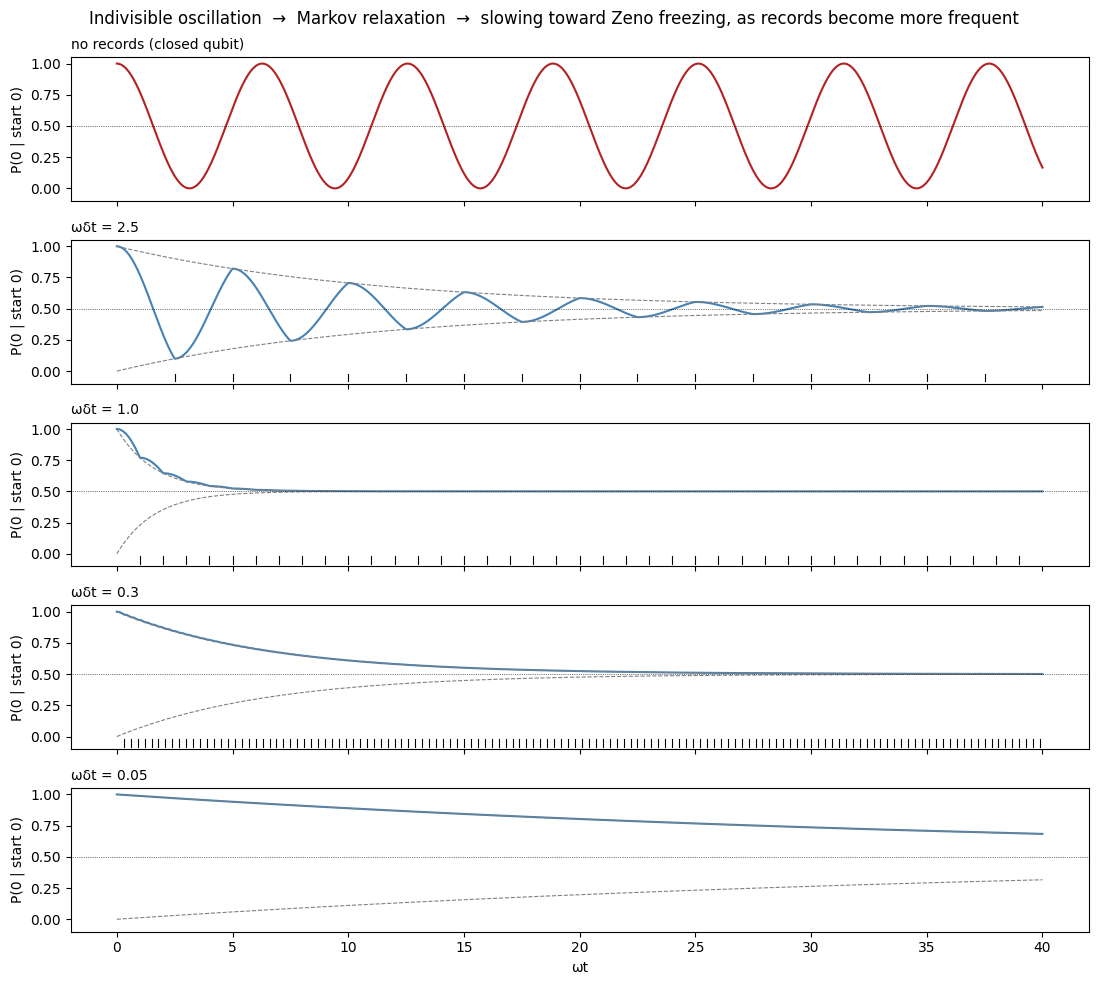

In [4]:
ts = np.linspace(0, 40, 4000)
spacings = [(np.inf, 'no records (closed qubit)'),
            (2.5, 'ωδt = 2.5'),
            (1.0, 'ωδt = 1.0'),
            (0.3, 'ωδt = 0.3'),
            (0.05, 'ωδt = 0.05')]

fig, axes = plt.subplots(len(spacings), 1, figsize=(11, 10), sharex=True)
for ax, (dt, label) in zip(axes, spacings):
    p = (1 + stretch(ts, dt)) / 2
    ax.plot(ts, p, color='firebrick' if np.isinf(dt) else 'steelblue')
    if not np.isinf(dt):
        env = np.abs(np.cos(OMEGA * dt)) ** (ts / dt)
        ax.plot(ts, (1 + env) / 2, '--', color='gray', lw=0.8)
        ax.plot(ts, (1 - env) / 2, '--', color='gray', lw=0.8)
        if dt >= 0.3:
            for tk in np.arange(dt, ts[-1], dt):
                ax.plot([tk, tk], [-0.08, -0.02], color='black', lw=0.8)
    ax.axhline(0.5, color='black', lw=0.5, ls=':')
    ax.set_ylim(-0.1, 1.05)
    ax.set_ylabel('P(0 | start 0)')
    ax.set_title(label, loc='left', fontsize=10)
axes[-1].set_xlabel('ωt')
plt.suptitle('Indivisible oscillation  →  Markov relaxation  →  slowing toward Zeno freezing, as records become more frequent')
plt.tight_layout()
plt.show()

### 📖 In depth: reading the five panels, top to bottom

- **No records (red).** The closed qubit from notebook 03: full oscillation forever. The start is forgotten at
  $\omega t = \pi/2$ and fully recovered at $\omega t = \pi$, over and over. Maximally indivisible.
- **$\omega\delta t = 2.5$.** Each interval shows a chunk of the oscillation, and inside it you can see the curve
  turn around. That turnaround is a revival of distinguishability, so it is indivisible between records. But
  each record shrinks the envelope by $|\cos 2.5| = 0.80$, and the oscillation slowly dies.
- **$\omega\delta t = 1.0$.** Records come before the curve can turn around. The curve decays toward ½ through
  kinks at the record times. It looks like a Markov chain, which, at the record times, it exactly is.
- **$\omega\delta t = 0.3$.** Smooth exponential decay: the "classical-looking" relaxation of a noisy system.
- **$\omega\delta t = 0.05$.** Decay so slow the system barely moves. This is the **quantum Zeno effect** (Misra and
  Sudarshan, 1977): the more often you check, the less it changes.

#### Why frequent checking freezes the system

In a short time $\tau$ the qubit's amplitude to have switched grows like $\omega\tau/2$, so the probability grows like
$(\omega\tau/2)^2$. That is *quadratic*: tiny for small $\tau$. Each record converts the amplitude into a
probability and restarts the clock. So $n$ records in time $T$ give total switching probability
$\approx n(\omega\,\delta t/2)^2 = (\omega^2 \delta t/4)\,T$, which goes to zero as $\delta t \to 0$. A process with no records
gets the full quadratic-then-oscillating growth. Quadratic short-time growth plus frequent restarts equals freezing.

<!-- expansion:06:deriv-zeno-factor -->
### 🧮 Worked derivation: switching rate versus forgetting rate (a factor of 2)

Above, the switching probability grows like $(\omega^2\delta t/4)\,T$; Section 3 gives the forgetting rate $\gamma \approx \omega^2\delta t/2$. Both are right.
Per interval the switching probability is $p \approx (\omega\delta t/2)^2$, but the gap is multiplied by $1 - 2p$: a switch removes probability
from the start *and* adds it to the other configuration. Over $T/\delta t$ intervals, $|\lambda| \approx e^{-2pT/\delta t}$, so $\gamma = 2p/\delta t \approx \omega^2\delta t/2$.

**Why the quadratic start matters.** If $p$ grew *linearly* in $\delta t$, as for a classical jump process, frequent checking would
change nothing. Freezing needs short-time switching to start quadratic, as unitary evolution does. Notebook 07 returns to this
short-time curvature of $\Gamma$.


<!-- expansion:06:howto-five-panels -->
### 🧭 How to use this cell / what to look at (the five-panel figure)

**What it computes.** $P(0 \mid \text{start } 0)$ for $0 \le \omega t \le 40$ at five spacings, perfect records. Dashed: the envelope. Ticks: record
times (not drawn at 0.05, which would need 800). Dotted ½: start forgotten.

**What to look at.** The cell prints no numbers, but the envelope at $\omega t = 40$ is $|\cos\omega\delta t|^{40/\omega\delta t}$, by hand about 0.029 (2.5),
$2\times10^{-11}$ (1.0), 0.002 (0.3) and 0.37 (0.05). The middle panels forget almost completely; the bottom one does not. Also note the
kinks at records in the 1.0 panel, and the turnarounds inside intervals in the 2.5 panel (Section 4's red stretches).

**Try this.** Add to `spacings`:
- `(np.pi / 2, 'ωδt = π/2')`. Prediction: reaches ½ at the first record and stays flat.
- `(np.pi, 'ωδt = π')`. Prediction: identical to the red top panel.
- `(2.0, 'ωδt = 2.0')`. Prediction: $\cos 2 \approx -0.42$, so values at successive records flip sides of ½ while shrinking.


<!-- expansion:06:recap-2 -->
### 📝 Recap: Section 2

- Same qubit, five spacings: undamped oscillation, damped oscillation with turnarounds, kinked Markov decay, smooth decay,
  near freezing.
- Each perfect record multiplies the gap by $\cos\omega\delta t$.
- Freezing comes from quadratic short-time switching restarted at every record.
- **Source.** The quantum Zeno effect is standard quantum mechanics, usually credited to Misra and Sudarshan (1977). The word
  "Zeno" does not appear in the three Barandes papers or the lecture transcript, nor is the effect discussed in the supplied
  Nielsen & Chuang text; Rivas et al. mention *"Zeno and anti-Zeno effects"* only in their outlook.


## 3. Forgetting Rate Versus Spacing

Each record multiplies the envelope by $|\cos\omega\delta t|$, so the relaxation rate is

$$\gamma(\delta t) = -\frac{\ln|\cos\omega\delta t|}{\delta t} \;\approx\; \frac{\omega^2\,\delta t}{2} \quad (\omega\delta t \ll 1).$$

Three landmarks:
- $\omega\delta t \to 0$: $\gamma \to 0$. Frequent perfect records freeze the configuration: the quantum Zeno effect (Misra and Sudarshan, 1977).
  $\gamma$ is the population-relaxation form of the repeated-measurement Zeno rate: twice the survival-probability rate
  $\omega^2\delta t/4$, because $\lambda$ is a population difference. Itano et al. (1990) measured the same $\cos^n$ product in a driven two-level ion.
- $\omega\delta t = \pi/2$: $\gamma = \infty$. Each record lands on a coin flip; one record erases the start.
- $\omega\delta t = \pi$: $\gamma = 0$. Each record lands when $|U(\delta t)|^2$ is a permutation. The records are
  transparent and the process is identical to the closed one. (Pimenta, arXiv:2505.08785, §V.3, notes that every passage
  of $\Gamma$ through a permutation matrix is a "proper" division event.)

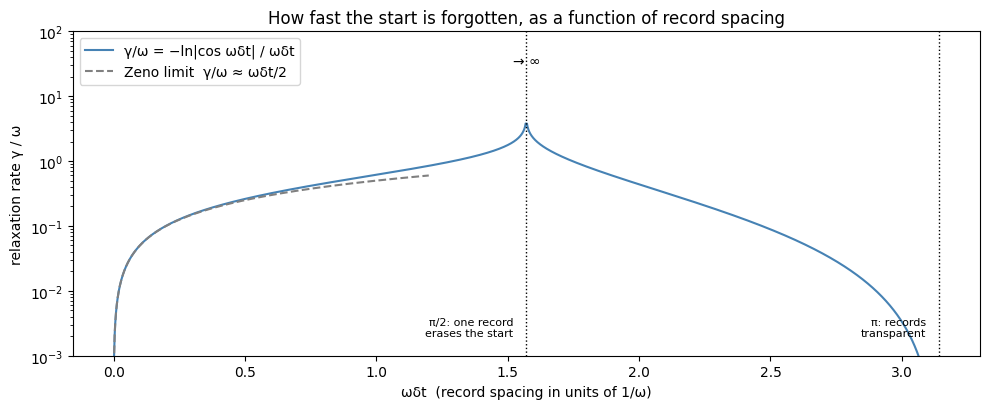

ωδt = π: max |λ_records − λ_closed| = 4.9e-15
ωδt = 0.3: γ/ω = 0.15231,  Zeno estimate 0.15000
ωδt = 0.05: γ/ω = 0.02501,  Zeno estimate 0.02500


In [5]:
x = np.linspace(1e-3, np.pi - 1e-3, 3000)
x = x[np.abs(x - np.pi / 2) > 2e-3]
rate = -np.log(np.abs(np.cos(x))) / x

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.semilogy(x, rate, color='steelblue', label='γ/ω = −ln|cos ωδt| / ωδt')
ax.semilogy(x[x < 1.2], x[x < 1.2] / 2, '--', color='gray', label='Zeno limit  γ/ω ≈ ωδt/2')
for xv, txt in [(np.pi / 2, 'π/2: one record\nerases the start'), (np.pi, 'π: records\ntransparent')]:
    ax.axvline(xv, color='black', ls=':', lw=1)
    ax.text(xv - 0.05, 2e-3, txt, ha='right', fontsize=8)
ax.set_xlabel('ωδt  (record spacing in units of 1/ω)')
ax.set_ylabel('relaxation rate γ / ω')
ax.set_ylim(1e-3, 1e2)
ax.annotate('→ ∞', xy=(np.pi / 2, 30), ha='center', fontsize=10)
ax.set_title('How fast the start is forgotten, as a function of record spacing')
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

ts = np.linspace(0, 40, 2001)
print(f'ωδt = π: max |λ_records − λ_closed| = {np.abs(stretch(ts, np.pi) - stretch(ts, np.inf)).max():.1e}')
for xv in (0.3, 0.05):
    print(f'ωδt = {xv}: γ/ω = {-np.log(np.abs(np.cos(xv))) / xv:.5f},  Zeno estimate {xv / 2:.5f}')

### 📖 In depth: deriving the rate, and the three landmarks

With perfect records, $\lambda$ at record times is $\cos(\omega\delta t)^{n}$ after $n$ records. Writing $n = t/\delta t$:

$$|\lambda(t)| = |\cos\omega\delta t|^{\,t/\delta t} = e^{-\gamma t}, \qquad \gamma = -\frac{\ln|\cos\omega\delta t|}{\delta t}.$$

For small $x = \omega\delta t$, $\ln\cos x \approx -x^2/2$, so $\gamma \approx \omega^2\delta t/2$. The time to forget (gap down to $1/e$) is
$1/\gamma \approx 2/(\omega^2\delta t)$. Example: $\omega\delta t = 0.05$ gives $1/\gamma \approx 40/\omega$, matching the bottom panel.

- **$\omega\delta t = \pi/2$: the fastest possible forgetting.** $|U(\delta t)|^2$ is exactly the coin flip $\frac12\begin{pmatrix}1&1\\1&1\end{pmatrix}$, so the
  first record already makes the configuration independent of the start. Records arriving exactly when the
  system is maximally uncertain lock that uncertainty in.
- **$\omega\delta t = \pi$: records that change nothing.** $|U(\pi)|^2$ is a perfect flip. Every record happens when the
  system is certainly in one configuration, so the witness learns nothing that wasn't already
  determined, and no interference is destroyed. The process is identical to the closed one (the check prints
  a difference of about $10^{-16}$). These are the *intrinsic* division events of the closed qubit: times when its
  evolution is a permutation. An environment that checks only then is invisible.
- **Between $\pi/2$ and $\pi$.** $\cos\omega\delta t < 0$, so the sign of $\lambda$ alternates every record: a damped flip-flop.
  The rate falls back toward 0 as records approach the transparent spacing.

#### The lesson for "how often"

"More division events" does **not** simply mean "more classical, faster relaxation." The effect of
records depends on *when* they land relative to the system's own motion. Rare records barely matter, moderate
ones produce ordinary Markov relaxation, and very frequent ones freeze the system.

<!-- expansion:06:howto-rate -->
### 🧭 How to use this cell / what to look at (the rate plot and its printout)

**What it computes.** $\gamma/\omega = -\ln|\cos x|/x$ against $x = \omega\delta t$ on a log scale, with the Zeno line $x/2$; points within 0.002 of $\pi/2$
are dropped (infinite rate).

**Which numbers matter.**
- `4.9e-15`: records at exactly $\omega\delta t = \pi$ leave the process unchanged to rounding error.
- `0.15231` vs `0.15000` at 0.3, and `0.02501` vs `0.02500` at 0.05: the Zeno estimate is about 1.5% low at 0.3. The series
  $-\ln\cos x/x = x/2 + x^3/12 + x^5/45 + \cdots$ gives $0.15 + 0.00225 + 0.00005 \approx 0.15230$, accounting for the gap.

**Try this.**
- Rates at $\omega\delta t = 1.0$ and $2.0$, computed as `-np.log(np.abs(np.cos(xv))) / xv` (the absolute value matters at 2.0, where
  $\cos$ is negative and the plain log gives `nan`). Prediction: about 0.616 and 0.438. Records at 2 forget *more slowly* than at 1.
- Rate at `np.pi/2 - 0.01`. Prediction: about 2.95, unbounded as you approach $\pi/2$.
- The $\pi$ comparison at `2 * np.pi`. Prediction: also about $10^{-15}$; $|U(2\pi)|^2$ is the identity.


<!-- expansion:06:recap-3 -->
### 📝 Recap: Section 3

- $\gamma = -\ln|\cos\omega\delta t|/\delta t$. In terms of record rate $r = 1/\delta t$, the Zeno regime gives $\gamma \approx \omega^2/(2r)$: doubling the recording rate halves the
  forgetting rate.
- $\omega\delta t = \pi/2$: one record erases the start. $\omega\delta t = \pi$: $|U|^2$ is a swap, the coherence is already zero at each record, and
  records change nothing (stored $4.9\times10^{-15}$).
- For $\pi/2 < \omega\delta t < \pi$, shortening the spacing *raises* the rate. This is only an analogy to the "anti-Zeno" effect
  (more frequent observation speeding up change): here the cause is simply where each record lands in the qubit's oscillation.


## 4. Where Divisibility Holds

For this family, a valid $\Gamma(t \leftarrow t')$ exists exactly when $|\lambda(t)| \le |\lambda(t')|$: a stochastic step
cannot increase the distance between two distributions. (This rule needs no inverse, so it also
covers singular $\Gamma(t' \leftarrow 0)$.)

Records make every $k\,\delta t$ a conditioning time. Between records $|\lambda|$ follows $|\cos\omega\tau|$, which is
non-increasing for $\omega\tau \le \pi/2$. Hence:

- $\omega\delta t \le \pi/2$: $|\lambda|$ never increases, and the process is divisible over **every** pair of times.
- $\omega\delta t > \pi/2$: $|\lambda|$ revives inside each interval, and indivisible pairs return.

**Prior work.** The threshold is known. The gap rule is the two-state case of Buscemi and Datta's theorem that a process
is divisible exactly when distinguishability never increases (Buscemi–Datta 2016, arXiv:1408.7062), and the $\pi/2$
threshold follows from it and from Pimenta's two-configuration analysis (arXiv:2505.08785).

<!-- expansion:06:deriv-gap-rule -->
### 🧮 Worked derivation: the gap rule, in both directions

**Necessary.** The two columns of $\Gamma(t' \leftarrow 0)$ differ by $(\lambda', -\lambda')$, L1 norm $2|\lambda'|$. A valid $M = \Gamma(t \leftarrow t')$ must map them to columns
differing by L1 norm $2|\lambda|$. For any stochastic $M$,

$$\|Mv\|_1 = \sum_i \Big|\sum_j M_{ij}v_j\Big| \le \sum_j \Big(\sum_i M_{ij}\Big)|v_j| = \|v\|_1,$$

so $|\lambda| \le |\lambda'|$ is required.

**Sufficient.** If $\lambda' \ne 0$, take the symmetric matrix with gap $\mu = \lambda/\lambda'$; $|\mu| \le 1$ keeps its entries $(1\pm\mu)/2$ in $[0, 1]$. If $\lambda' = 0$,
then $\lambda = 0$ and the coin flip $\frac12\begin{pmatrix}1&1\\1&1\end{pmatrix}$ works. No inverse is used, which is why the rule covers singular cases.

**Source.** This is the 2×2 case of Rivas, Huelga & Plenio, §2.3, Theorem 2.4: a classical process *"is divisible if and only if
the L1-norm does not increase"* (eq. 19), for every vector. The quantum Breuer–Laine–Piilo criterion (monotone trace distance,
eq. 55) works only one way: divisibility of the quantum map implies it, but *"the reverse implication fails to hold"* (§3.4). For
the symmetric 2×2 family here, the single distance between the two starts already decides divisibility, as the sufficiency
argument above shows. The equivalence of divisibility and never-increasing distinguishability, classical and quantum, is
Buscemi and Datta's theorem (Buscemi–Datta 2016, arXiv:1408.7062).


largest invalid fraction for ωδt <= π/2: 0
invalid fraction with no records:        0.511
gap rule agrees with the LP test on 50 of 50 random pairs


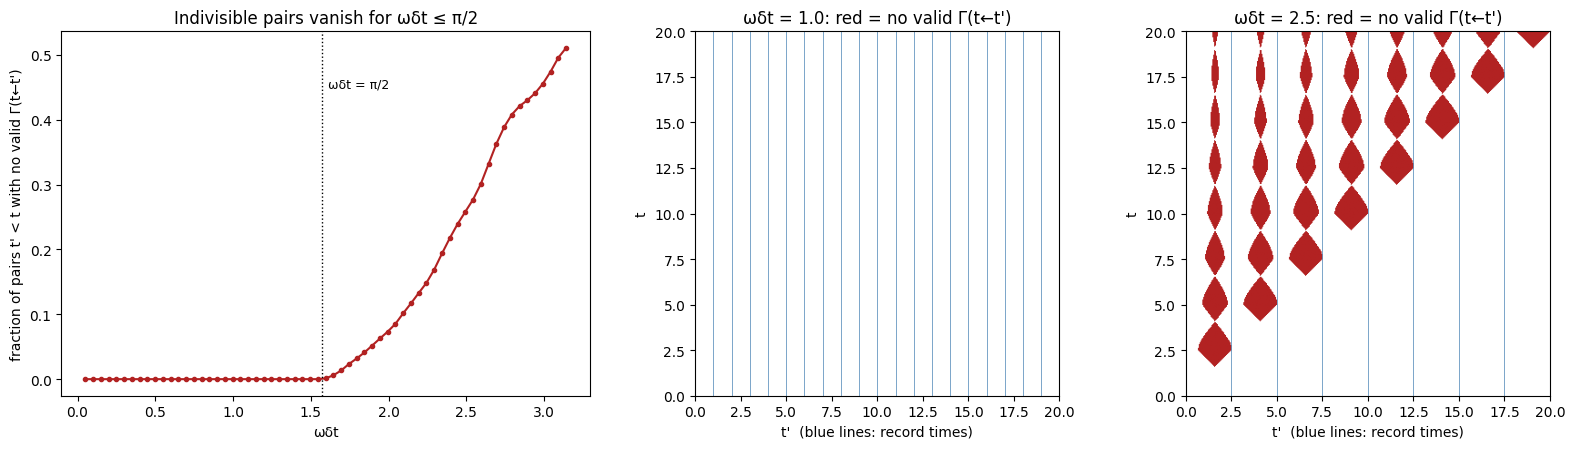

In [6]:
grid = np.linspace(0, 20, 401)
upper = np.triu(np.ones((grid.size, grid.size), bool), k=1)


def invalid_pairs(dt):
    L = np.abs(stretch(grid, dt))
    return (L[None, :] > L[:, None] + 1e-9) & upper     # row t', column t


x = np.linspace(0.05, np.pi, 63)
frac = [invalid_pairs(xv).sum() / upper.sum() for xv in x]
print(f'largest invalid fraction for ωδt <= π/2: {max(f for f, xv in zip(frac, x) if xv <= np.pi / 2 + 1e-12):.3g}')
print(f'invalid fraction with no records:        {invalid_pairs(np.inf).sum() / upper.sum():.3f}')

from matplotlib.colors import ListedColormap

rng = np.random.default_rng(6)
checks = []
for xv in (1.0, 2.5):
    bad = invalid_pairs(xv)
    for _ in range(25):
        i, j = sorted(rng.choice(grid.size, 2, replace=False))
        checks.append(divides(grid[i], grid[j], xv) == (not bad[i, j]))
print(f'gap rule agrees with the LP test on {sum(checks)} of {len(checks)} random pairs')

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), gridspec_kw={'width_ratios': [1.3, 1, 1]})
axes[0].plot(x, frac, 'o-', ms=3, color='firebrick')
axes[0].axvline(np.pi / 2, color='black', ls=':', lw=1)
axes[0].text(np.pi / 2 + 0.04, 0.45, 'ωδt = π/2', fontsize=9)
axes[0].set_xlabel('ωδt'); axes[0].set_ylabel("fraction of pairs t' < t with no valid Γ(t←t')")
axes[0].set_title('Indivisible pairs vanish for ωδt ≤ π/2')
for ax, xv in zip(axes[1:], (1.0, 2.5)):
    ax.imshow(invalid_pairs(xv).T, origin='lower', extent=[0, 20, 0, 20],
              cmap=ListedColormap(['white', 'firebrick']), vmin=0, vmax=1)
    for tk in np.arange(xv, 20, xv):
        ax.axvline(tk, color='steelblue', lw=0.5)
    ax.set_xlabel("t'  (blue lines: record times)"); ax.set_ylabel('t')
    ax.set_title(f"ωδt = {xv}: red = no valid Γ(t←t')")
plt.tight_layout()
plt.show()

### 📖 In depth: why the threshold is exactly $\omega\delta t = \pi/2$

The rule (notebook 03): a valid $\Gamma(t \leftarrow t')$ exists iff $|\lambda(t)| \le |\lambda(t')|$.

- **Across a record**, $|\lambda|$ is continuous, and the record only resets the clock: $|\lambda|$ restarts at its
  current value and then follows $|\lambda_k|\,|\cos\omega\tau|$.
- **Inside one interval**, $|\cos\omega\tau|$ for $0 \le \omega\tau \le \omega\delta t$ is non-increasing iff the interval never reaches past
  $\omega\tau = \pi/2$ (where cosine hits 0 and $|\cos|$ starts rising again).
- So if $\omega\delta t \le \pi/2$, $|\lambda(t)|$ never increases anywhere, and **every** pair satisfies the rule. If
  $\omega\delta t > \pi/2$, every interval contains a stretch where $|\lambda|$ rises, and the pairs straddling it fail.

#### Two easily confused statements

- For $\omega\delta t \le \pi/2$ the process is **divisible at every time** as a matter of mathematics.
- But **physical division events** still happen only at the record times $k\,\delta t$. In between, the
  laws don't contain a conditioning time; it just happens that a valid matrix exists.

The maps show this. For $\omega\delta t = 2.5$ the red columns sit at $t'$ values near $\omega\tau = \pi/2$ inside each interval, where
$|\lambda|$ dips toward 0 before reviving. Columns with $t'$ exactly on a blue record line are always white. For $\omega\delta t = 1.0$
the whole map is white.

<!-- expansion:06:howto-divisibility-map -->
### 🧭 How to use this cell / what to look at (fractions, cross-check, and the two maps)

**What it computes.** 401 grid times on $[0, 20]$ give 80,200 pairs $t' < t$. `invalid_pairs` marks those breaking the gap rule.

**Which numbers matter.**
- `0` for every spacing up to $\pi/2$: not one failing pair.
- `0.511` with no records: $|\cos\omega t|$ spends half its time rising, so about half the pairs fail.
- `50 of 50`: the gap rule and the LP test agree on 25 random pairs at 1.0 and 25 at 2.5.

**In the figure.** Left: zero until the dotted $\pi/2$ line. Middle (1.0): all white. Right (2.5): red bands at mid-interval $t'$, never on a
blue record line. Read a column as "from this $t'$, which later $t$ are unreachable".

**Try this.**
- `invalid_pairs(np.pi / 2 + 0.1).sum() / upper.sum()`. Prediction: small but non-zero (around 1%).
- The same at `np.pi`. Prediction: 0.511, as with no records, since records at $\pi$ are transparent.


<!-- expansion:06:recap-4 -->
### 📝 Recap: Section 4

- Gap rule: a valid $\Gamma(t \leftarrow t')$ exists iff $|\lambda(t)| \le |\lambda(t')|$, the 2×2 case of L1 contraction.
- Records restart free evolution; inside an interval $|\lambda|$ follows $|\cos|$, which only rises past $\pi/2$.
- $\omega\delta t \le \pi/2$: every pair divisible (stored fraction 0). No records: 0.511 of pairs fail. The threshold is known
  (Buscemi–Datta 2016; Pimenta, arXiv:2505.08785).
- Divisible-at-every-time is mathematics; physical division events are still only the record times.


## 5. Imperfect Records

With overlap $c > 0$ a record only partly separates the environment's branches. The system's
coherence is multiplied by $c$ at each record instead of being erased, and the record times are no
longer guaranteed to be division events.

Measure the failure directly: after each record time $k\,\delta t$, how much distinguishability comes back,

$$R = \max_{k}\;\max_{t > k\delta t}\Big(|\lambda(t)| - |\lambda(k\,\delta t)|\Big)_{+}.$$

$R = 0$ means a valid $\Gamma(t \leftarrow k\,\delta t)$ exists from every record time checked; with perfect records ($c = 0$)
the record times are exact division events. $R > 0$ means some record time is not an exact division event.
Since $|\lambda(t)|$ is the Kolmogorov distance between the runs started in 0 and in 1, $R$ is the maximal revival of that
distance after a record time: the classical memory witness of Smirne, Stabile and Vacchini (arXiv:1211.5913), evaluated
after record times.

**Prior work.** Barandes notes that division events are "generically always approximate" and become nearly exact when the
environment is sufficiently macroscopic (Paper 1, §3.7 and fn. 18, p. 19). Paper 3 (§2.2, p. 10) adds that they may be
"generated to an extremely good approximation through interactions with other systems." Whether a time is a
division event is a property of $\Gamma$ alone (Paper 2, eq. 35). Approximate division events, valid up to a stated level
of precision, are treated by Barandes, Hasan and Kagan (arXiv:2512.18105, §3.1). Measures of divisibility stated in
$\Gamma$ alone exist (Buscemi–Datta 2016, arXiv:1408.7062; Smirne, Stabile and Vacchini 2013, arXiv:1211.5913). Calvo
(arXiv:2601.18720, §5.1) ties exactness to a one-to-one match between environment and system configurations, and Smirne
et al. (2019, arXiv:1709.05267) give a related criterion for when repeated-measurement statistics are classical. Not found
in our searches: a physical sufficient condition on system plus environment, stated in transition probabilities, that
guarantees approximate division events at a given precision.

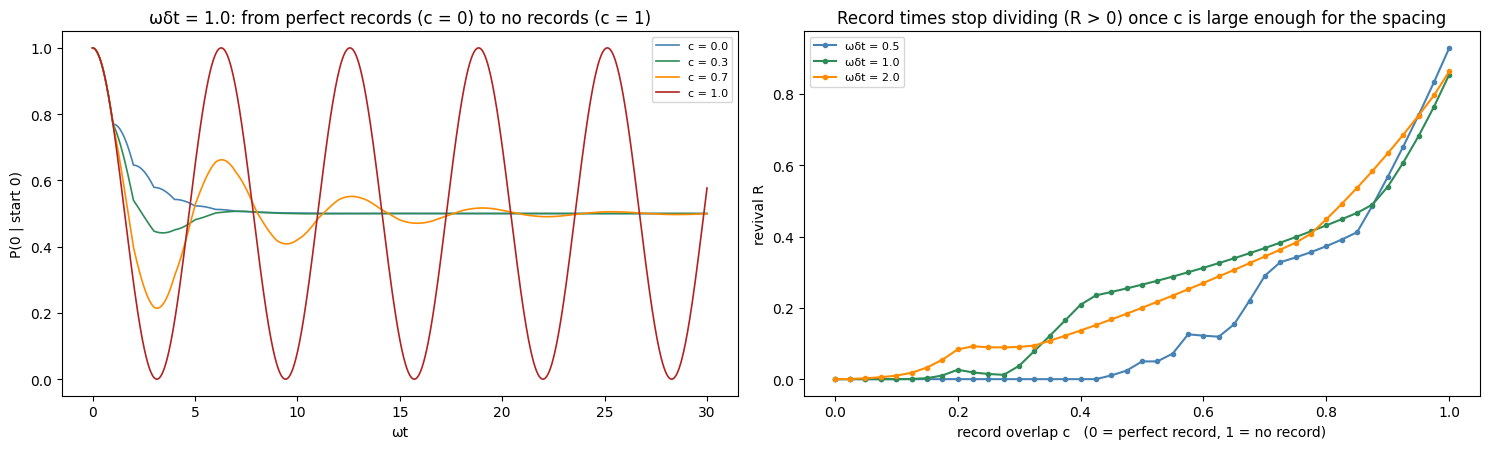

ωδt = 0.5: R(c=0) = 0.0e+00,  R(c=0.5) = 0.050,  R(c=1) = 0.929
ωδt = 1.0: R(c=0) = 0.0e+00,  R(c=0.5) = 0.265,  R(c=1) = 0.854
ωδt = 2.0: R(c=0) = 0.0e+00,  R(c=0.5) = 0.200,  R(c=1) = 0.863


In [7]:
dt = 1.0
ts = np.linspace(0, 30, 3000)


def revival(dt, c, n_records=8, t_max=30.0):
    worst = 0.0
    for k in range(1, n_records + 1):
        tk = k * dt
        later = np.linspace(tk, t_max, 600)[1:]
        worst = max(worst, np.abs(stretch(later, dt, c)).max() - abs(stretch(tk, dt, c)[0]))
    return max(worst, 0.0)


fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
for c, color in [(0.0, 'steelblue'), (0.3, 'seagreen'), (0.7, 'darkorange'), (1.0, 'firebrick')]:
    axes[0].plot(ts, (1 + stretch(ts, dt, c)) / 2, color=color, lw=1.2, label=f'c = {c}')
axes[0].set_xlabel('ωt'); axes[0].set_ylabel('P(0 | start 0)')
axes[0].set_title('ωδt = 1.0: from perfect records (c = 0) to no records (c = 1)')
axes[0].legend(fontsize=8)

cs = np.linspace(0, 1, 41)
for xv, color in [(0.5, 'steelblue'), (1.0, 'seagreen'), (2.0, 'darkorange')]:
    axes[1].plot(cs, [revival(xv, c) for c in cs], 'o-', ms=3, color=color, label=f'ωδt = {xv}')
axes[1].set_xlabel('record overlap c   (0 = perfect record, 1 = no record)')
axes[1].set_ylabel('revival R')
axes[1].set_title('Record times stop dividing (R > 0) once c is large enough for the spacing')
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

for xv in (0.5, 1.0, 2.0):
    print(f'ωδt = {xv}: R(c=0) = {revival(xv, 0.0):.1e},  R(c=0.5) = {revival(xv, 0.5):.3f},  R(c=1) = {revival(xv, 1.0):.3f}')

### 📖 In depth: imperfect records and "generically approximate" division events

Paper 1, footnote 18: *"Although generically always approximate, division events will become nearly exact
when the environment is sufficiently macroscopic, for precisely the same reasons that decoherence becomes
nearly exact in such cases."*

This section illustrates that sentence in one model:

- **Left panel.** $c = 0$ is the Markov curve from Section 2. $c = 1$ is the closed qubit. In between, the
  oscillation survives partially.
- **Right panel.** $R$ is the largest amount of distinguishability that comes back after a record time. If $R > 0$,
  that record time is **not** an exact division event: some of the "memory" leaked past the record.
  - $R = 0$ at $c = 0$ (perfect records), and broadly grows with $c$ (not perfectly smoothly: which revival is largest depends on where the records land).
  - For short spacings $R$ stays at 0 up to a sizeable $c$ (up to $c = 0.45$ at $\omega\delta t = 0.5$, $0.1$ at $1.0$, $0.025$ at $2.0$).
    Partial records that come often enough still prevent any revival, because the qubit never gets far enough
    between records to turn around. So $c > 0$ does not by itself make the record times fail to divide.
  - $R$ is the classical Kolmogorov-distance memory witness of Smirne, Stabile and Vacchini (arXiv:1211.5913),
    evaluated after record times; $|\lambda|$ is exactly the Kolmogorov distance between the two starts.

#### Why a macroscopic environment makes $c$ tiny

A real environment records with many particles at once, not one witness qubit. If each of $N$ air molecules
scattering off an object carries a little information, the total overlap is a product, $c = c_1 c_2 \cdots c_N$, which
is exponentially small in $N$. That is the standard reason decoherence is so effective for large objects, and
the reason Barandes says division events become "nearly exact." This notebook's single-witness model can't
show the $N$-dependence. It shows only what a given $c$ does.

#### Connection to the lecture

In the Q&A (~66–70 min) Barandes cites Glick and Adami: a chain of measurement-like interactions by
*mesoscopic* devices gives slightly different predictions from literal collapse, with the difference
shrinking as the devices become large and strongly coupled to their environment. In this notebook's language:
mesoscopic devices produce records with $c$ small but non-zero, so the division events can be approximate, and $R$
measures the discrepancy when it shows up as a revival.

<!-- expansion:06:howto-revival -->
### 🧭 How to use this cell / what to look at (record quality $c$ and revival $R$)

**What it computes.** Left: $P(0 \mid \text{start } 0)$ at $\omega\delta t = 1.0$ for four values of $c$. Right: $R$ against $c$ at three spacings, using the first
8 records and 599 later times up to $\omega t = 30$ (so $R = 0$ means "no violation on this grid"). By the gap rule, $R = 0$ exactly when
every checked record time admits a valid $\Gamma(t \leftarrow k\delta t)$.

**Which numbers matter.**
- `R(c=0) = 0`: perfect records are exact division events.
- `R(c=0.5)` = 0.050, 0.265, 0.200 at $\omega\delta t$ = 0.5, 1.0, 2.0: not ordered by spacing, since it depends where records land.
- `R(c=1)` = 0.929, 0.854, 0.863: no records, so closed-qubit numbers. By hand: the worst record time has the smallest $|\cos(k\,\omega\delta t)|$
  for $k \le 8$ and $|\lambda|$ later returns to about 1. So $1 - |\cos 1.5| \approx 0.929$, $1 - |\cos 8| \approx 0.854$, $1 - |\cos 14| \approx 0.863$.

**Divisible versus guaranteed.** With $c > 0$, $R = 0$ says a valid factor $\Gamma(t \leftarrow k\delta t)$ *exists* on the tested grid, so by
the $\Gamma$-level definition (Paper 2, eq. 35) the record time still divides there. What is lost is the guarantee: Paper 1's
derivation needs a perfect record (eq. 45), and the factor is no longer the $|U(\tau)|^2$ a perfect record would give. So $c > 0$
alone does not make a record time fail; $R > 0$ does. Section 4's "Two easily confused statements" draws a similar line.

**Try this.**
- `revival(1.0, 0.1)`. Prediction: essentially 0 (order $10^{-5}$).
- `revival(1.0, 1.0, n_records=20)`. Prediction: $R$ cannot decrease with more records; it rises from 0.854 to near 1.


<!-- expansion:06:recap-5 -->
### 📝 Recap: Section 5

- An imperfect record multiplies coherence by $c$ rather than erasing it, so division at record times is no longer guaranteed.
- $R$ (Smirne, Stabile and Vacchini's Kolmogorov-distance witness, arXiv:1211.5913) measures the failure: 0 for $c = 0$;
  0.050 / 0.265 / 0.200 at $c = 0.5$; closed-qubit values at $c = 1$.
- Short spacings tolerate blurry records, because the qubit cannot turn around between them: $R = 0$ up to $c = 0.45$ at $\omega\delta t = 0.5$.
- This illustrates Paper 1's footnote 18 in one model, and these records are phase damping with $c = \sqrt{1 - \lambda_{\rm NC}}$ (notebook 08).


### 🔭 Looking ahead: what this says about the classical regime, and what it doesn't

**What the notebook supports.**

- **The classical regime is where records are frequent.** Macroscopic objects are recorded by their
  environment on time scales far shorter than any motion we observe, so they sit at small $\omega\delta t$ with $c \approx 0$.
  The divisibility threshold puts them firmly in the divisible region. Indivisibility is still there between
  records, but squeezed into intervals too short to matter. This matches Barandes's account of why Markov
  models work (Paper 1, §3.7).
- **Indivisibility needs isolation, not smallness.** What matters is $\omega\delta t$ and $c$, not size as such. Isolated
  qubits, trapped ions, and molecules in interferometers have long gaps between records; that is why they
  show interference.
- **Distinguishability revival is the signature of indivisibility.** "Information coming back" ($R > 0$, or the turnarounds in
  Section 2) is what makes $\Gamma$ indivisible. The open-quantum-systems counterpart is the Breuer–Laine–Piilo (BLP)
  signature, a revival of the trace distance between two evolving density matrices. The two are different quantities:
  here the density-matrix map (rotation between records, dephasing at each record) is a composition of valid quantum
  channels, so its trace distances never revive, while $\Gamma$ does show revivals. Notebook 08 compares the two notions.
  Barandes makes the general point himself: indivisible processes are not "non-Markovian only in the familiar sense"
  (Paper 3, §1). The detailed comparison is in the open-systems literature (Vacchini, Smirne, Laine, Piilo and Breuer, 2011;
  Benatti et al. 2024, arXiv:2405.05794).

**What the notebook does not settle.**

- **Very frequent records and smooth motion.** Ideal, instantaneous records in the configuration basis freeze the
  dynamics when they are very frequent, yet macroscopic objects plainly move. The usual resolution is that real records are
  coarse-grained (position to within some cell, not exactly) and imperfect. The word "Zeno" does not appear in
  the three papers or in the lecture transcript, so how Barandes's framework recovers smooth classical motion under
  very frequent records is not addressed here; worth checking in his newer papers.
- **One witness per record, never interacting again** is the most idealized environment possible. Real
  environments have their own dynamics and can feed information back.
- **Two states only.** The divisibility threshold and closed forms are specific to this 2×2 family.

<!-- expansion:06:papers-decoherence-measurement -->
### 📚 From the papers: decoherence and measuring devices in Barandes's terms

- **Paper 1, §3.8 "Decoherence".** The environment *"has effectively eliminated the off-diagonal entries"*, and decoherence is
  *"nothing more than the mundane leakage of correlations into the environment"* seen in Hilbert-space terms. Coherences are
  *"merely indications that one is catching a given system when it is in the midst of an indivisible stochastic process,
  between division events."* Here, with perfect records, the Bloch $y$ component is zero at each record and non-zero only between records.
- **Paper 1, §4.4.** A good measuring device *"should be in sufficiently strong contact with a noisy environment to generate a
  robust division event at the conclusion of the measurement interaction."* Paper 1 gives no numerical criterion for "robust";
  this lab interprets it as a record with small $c$ and negligible $R$.
- **Nielsen & Chuang, §8.3.6** raise the parallel textbook question: *"Perhaps it is phase damping that is responsible for this
  absence of superposition states from the everyday"*.
- The comparison with Breuer–Laine–Piilo non-Markovianity in the cell above is not in Barandes's papers in this form, though
  he notes that indivisible processes are not "non-Markovian only in the familiar sense" (Paper 3, §1). The open-systems
  literature had already compared the two notions (Vacchini, Smirne, Laine, Piilo and Breuer, 2011; Benatti et al. 2024).


## Summary

- A recording environment produces division events with no extra postulate: the full unitary on
  system plus environment, marginalized, gives a transition matrix that divides at every record time.
  This reproduces Paper 1, §3.7.
- With perfect records every $\delta t$ the process is a Markov chain at the record times (Paper 1, eq. 57),
  and one number, $\omega\delta t$, sets its behaviour.
- $\omega\delta t \le \pi/2$: divisible over every pair of times. $\omega\delta t > \pi/2$: indivisible between records.
- The relaxation rate $-\ln|\cos\omega\delta t|/\delta t$ is not monotone in the record rate. It vanishes as
  $\delta t \to 0$ (Zeno), diverges at $\omega\delta t = \pi/2$, and vanishes again at $\omega\delta t = \pi$, where the records are transparent.
- Imperfect records ($c > 0$) no longer guarantee division events. Record times fail to divide ($R > 0$) once $c$ is
  large enough for the spacing, though short spacings tolerate fairly blurry records. Paper 1 (fn. 18) anticipates
  that division events are generically approximate.

Caveat: the Zeno freezing follows from *ideal, instantaneous, configuration-basis* records in this
two-state model. How smooth classical motion survives very frequent, realistic (coarse-grained,
imperfect) records is not addressed here.

**Prior work.** None of the results here is new. Records making division events is Paper 1's own construction (§3.7).
The forgetting rate is the population-relaxation form of the repeated-measurement Zeno rate (Misra and Sudarshan, 1977;
Itano et al., 1990). The $\omega\delta t \le \pi/2$ threshold follows from Buscemi and Datta's divisibility criterion
(Buscemi–Datta 2016) and from Pimenta (arXiv:2505.08785). The revival $R$ is Smirne, Stabile and Vacchini's
Kolmogorov-distance witness (arXiv:1211.5913). That division events are approximate is Barandes's own point (Paper 1,
fn. 18), and approximate division events at a stated precision appear in Barandes, Hasan and Kagan (arXiv:2512.18105, §3.1).
What the notebook adds is a worked, fully simulated example.

### 📖 In depth: the answer to "how often, and what limits it," in one place

- **What sets the rate:** how strongly and how often the environment records the configuration. In this
  model it is the record spacing $\delta t$ and quality $c$.
- **What matters physically:** the ratio $\omega\delta t$, not $\delta t$ alone.
- **Lower limit (rare records):** nothing forces them. An isolated system can go a long time with no division
  event, and is then indivisible over long intervals.
- **Upper limit (very frequent records):** ideal records freeze the dynamics (Zeno). Real classical motion
  therefore needs records that are frequent but not ideal, which this notebook does not address.
- **Exactness:** only perfect records ($c = 0$) guarantee exact division events (Paper 1, eq. 45). With $c > 0$ the
  record times can fail to divide ($R > 0$), depending on $c$ and the spacing. Macroscopic environments make $c$
  exponentially small (Paper 1, fn. 18).
- **Special timing:** records at $\omega\delta t = \pi/2$ are maximally destructive, and records at $\omega\delta t = \pi$ are invisible.

<!-- expansion:06:final-recap -->
### 📝 Notebook recap and where to go next

**What you can now do.**
- Derive a division event from unitary evolution plus marginalization, naming the assumptions that do the work: orthogonal
  witness states (Paper 1, eq. 45) that never interact again (eq. 46).
- Write the perfect-record process from one number: $\lambda(t) = \cos(\omega\delta t)^k\cos(\omega(t-k\delta t))$, with $\gamma \approx \omega^2\delta t/2$ for small spacing.
- Decide divisibility of any pair with the gap rule, and quantify imperfect records with $R$.

**Caveats to carry forward.** One qubit, one idealised witness per record, instantaneous configuration-basis records. The
Zeno freezing depends on these idealisations, and the sources used here do not say how realistic records avoid freezing
macroscopic motion.

**Where to go next.**
- **Notebook 07** turns an energy–time uncertainty relation written only in $\Gamma$ into a speed limit on how fast
  distinguishability can *come back*, the quantity Section 5 measured, and reads an "agility" off the curvature of $\Gamma$ at $t = 0$,
  the same short-time behaviour behind the Zeno effect.
- **Notebook 08** shows these records are N&C's phase damping channel with $c = \sqrt{1-\lambda}$, and maps where Barandes's divisibility and
  the textbook's Markovianity agree and disagree.
- **Pencil-and-paper companion:** N&C Exercise 8.26 (show the Figure 8.15 circuit implements phase damping) is the textbook
  version of `gamma_environment`.
